# Fase 3 — Simulación de Trayectorias de Precio (Cap. 5)

Con la posterior del modelo SV estimada en la Fase 2, generamos trayectorias de precio
futuras que **propagan la incertidumbre paramétrica** (epistémica) además de la aleatórica,
y las comparamos con la línea base **KDE-Bootstrap i.i.d.**

> **Hipótesis (plan §5.2):** el SV, al ser *condicional* al estado de volatilidad actual
> ($h_T$ al final del train) y capturar clustering, difiere del bootstrap i.i.d. — sobre todo
> en **horizontes cortos**. A largo plazo el SV revierte a su volatilidad incondicional.

Ambos modelos se simulan **sin deriva** (zero-drift) para aislar la dinámica de volatilidad:
el SV se estimó sobre retornos centrados y el bootstrap usa `drift_mode='zero'`.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../..'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt

from tesis.data import loader
from tesis.bayesian.sv_model.stochastic_volatility import fit_sv_pymc, idata_to_mcmc_result
from tesis.bayesian.sv_model.trajectory_simulator import simulate_sv_trajectories_fast, summarize_sv_risk
from tesis.baseline.mc_bootstrap.simulator import MonteCarloPriceSimulator, BiasConfig

plt.style.use('seaborn-v0_8-whitegrid'); plt.rcParams['figure.figsize']=(12,4)
SEED=42; N_SIMS=4000

## 1. Setup: datos y reestimación del SV (NUTS)

Reestimamos el SV sobre el train (2012–2023) con la configuración de referencia de la Fase 2
(`2000×4, tune=3000, target_accept=0.99`) y lo convertimos al formato que consume el simulador.

In [2]:
price = loader.load_price_series('BTC','1D')
ret = loader.compute_log_returns(price)
SPLIT='2024-01-01'
price_tr, price_te = loader.split_train_test(price, SPLIT)
ret_tr,   ret_te   = loader.split_train_test(ret,   SPLIT)
mu_ret = ret_tr.mean()
y_train = (ret_tr - mu_ret).values
start_price = float(price_tr.iloc[-1])

idata = fit_sv_pymc(y_train, n_samples=2000, n_chains=4, target_accept=0.99, tune=3000, seed=SEED)
mcmc = idata_to_mcmc_result(idata)

print(f'Precio inicial (fin train): ${start_price:,.0f}')
print(f'Muestras posteriores: {len(mcmc["mu"])}')
print(f'Posterior media: mu={mcmc["mu"].mean():.3f}, phi={mcmc["phi"].mean():.3f}, sigma_eta={mcmc["sigma_eta"].mean():.3f}')
h_last = mcmc['h'][:, -1]
vol0 = np.exp(np.median(h_last)/2)*np.sqrt(252)
print(f'Vol. anualizada del estado inicial h_T: {vol0:.1%} (condiciona la simulación SV)')

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [mu, phi_raw, sigma_eta_sq, h]


Sampling 4 chains for 3_000 tune and 2_000 draw iterations (12_000 + 8_000 draws total) took 119 seconds.


The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


Precio inicial (fin train): $42,639
Muestras posteriores: 8000
Posterior media: mu=-7.209, phi=0.903, sigma_eta=0.578
Vol. anualizada del estado inicial h_T: 23.4% (condiciona la simulación SV)


## 2. Trayectorias con la posterior SV (horizonte 365 días)

Para cada trayectoria se toma una muestra posterior $(\mu^*,\phi^*,\sigma_\eta^*)$ y su $h_T^*$,
se simula la log-volatilidad hacia adelante y de ahí los log-retornos y el precio.

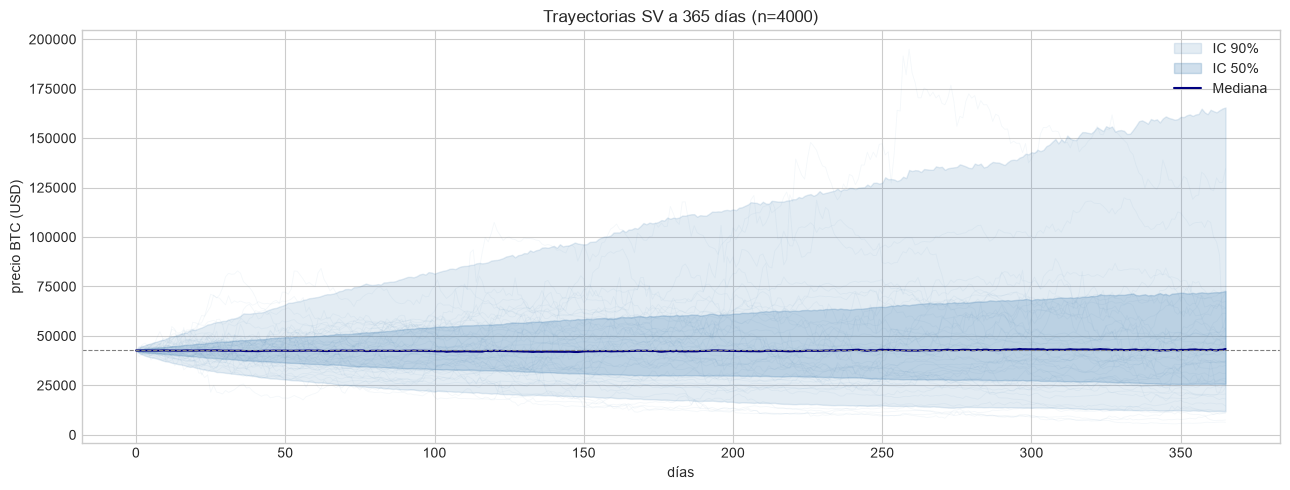

In [3]:
H=365
sv_paths = simulate_sv_trajectories_fast(mcmc, start_price, horizon_steps=H, n_trajectories=N_SIMS, seed=1)

qs=[5,25,50,75,95]
sv_pct = {q: sv_paths.quantile(q/100, axis=1) for q in qs}
fig,ax=plt.subplots(figsize=(13,5))
for c in np.random.default_rng(0).choice(sv_paths.shape[1], 40, replace=False):
    ax.plot(sv_paths.index, sv_paths[c], color='steelblue', alpha=0.06, linewidth=0.6)
ax.fill_between(sv_paths.index, sv_pct[5], sv_pct[95], color='steelblue', alpha=0.15, label='IC 90%')
ax.fill_between(sv_paths.index, sv_pct[25], sv_pct[75], color='steelblue', alpha=0.25, label='IC 50%')
ax.plot(sv_paths.index, sv_pct[50], color='navy', linewidth=1.5, label='Mediana')
ax.axhline(start_price, color='gray', linestyle='--', linewidth=0.8)
ax.set_title(f'Trayectorias SV a {H} días (n={N_SIMS})'); ax.set_xlabel('días'); ax.set_ylabel('precio BTC (USD)'); ax.legend()
plt.tight_layout(); plt.show()

## 3. Línea base: KDE-Bootstrap i.i.d.

Método de la línea base (`baseline/mc_bootstrap`): remuestrea log-retornos históricos + ruido KDE,
asumiendo retornos **i.i.d.** (rompe el clustering temporal). Mismo horizonte y `n_sims`.

In [4]:
bias = BiasConfig(use_log_returns=True, drift_mode='zero')  # zero-drift, comparable al SV centrado
mc = MonteCarloPriceSimulator(price_tr, n_sims=N_SIMS, bias=bias)
bs_paths = mc.simulate_paths(H)
bs_pct = {q: bs_paths.quantile(q/100, axis=1) for q in qs}
print(f'Bootstrap: {bs_paths.shape[1]} trayectorias, horizonte {H} días, retornos i.i.d.')

Bootstrap: 4000 trayectorias, horizonte 365 días, retornos i.i.d.


## 4. SV vs Bootstrap: distribución de precios finales y riesgo (365 d)

                         SV (Bayesiano)  Bootstrap i.i.d.
p05_final_price             11,875.4259       10,367.8400
median_final_price          43,398.0377       43,080.7599
p95_final_price            165,511.9093      162,781.4523
prob_drop_20pct_or_more          0.3807            0.3965
prob_drop_40pct_or_more          0.2435            0.2692
prob_drop_50pct_or_more          0.1792            0.2042


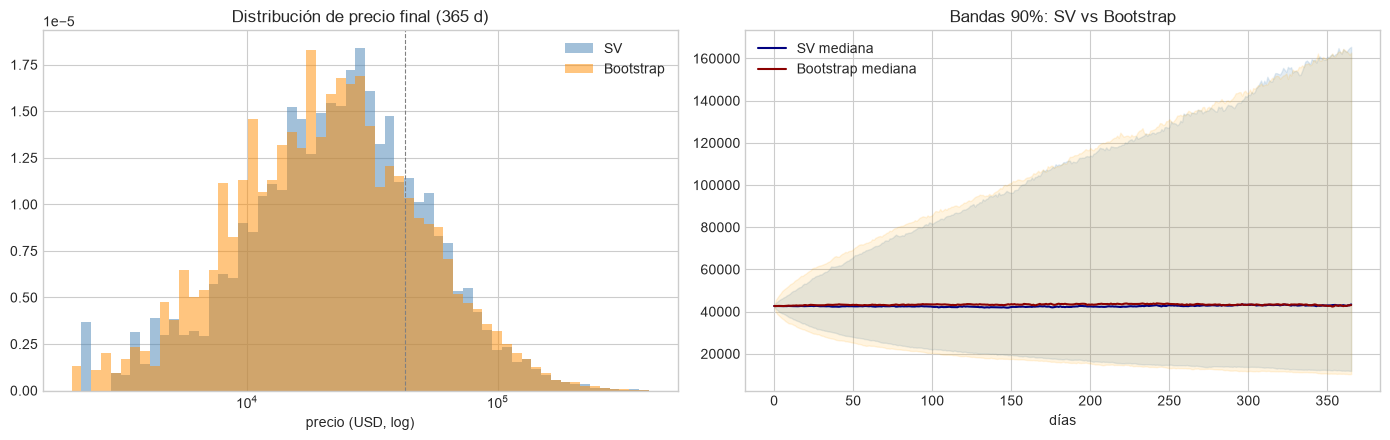

In [5]:
sv_r = summarize_sv_risk(sv_paths, init_ltv=0.50, liq_ltv=0.80)
bs_r = MonteCarloPriceSimulator.summarize_risk(bs_paths)
keys=['p05_final_price','median_final_price','p95_final_price','prob_drop_20pct_or_more','prob_drop_40pct_or_more','prob_drop_50pct_or_more']
cmp = pd.DataFrame({
  'SV (Bayesiano)':[sv_r[k] for k in keys],
  'Bootstrap i.i.d.':[bs_r[k] for k in keys],
}, index=keys)
print(cmp.to_string(float_format=lambda x: f'{x:,.4f}'))

fig,axes=plt.subplots(1,2,figsize=(14,4.5))
final_sv=sv_paths.iloc[-1].values; final_bs=bs_paths.iloc[-1].values
bins=np.logspace(np.log10(2000), np.log10(400000), 60)
axes[0].hist(final_sv, bins=bins, alpha=0.5, density=True, label='SV', color='steelblue')
axes[0].hist(final_bs, bins=bins, alpha=0.5, density=True, label='Bootstrap', color='darkorange')
axes[0].axvline(start_price, color='gray', ls='--', lw=0.8)
axes[0].set_xscale('log'); axes[0].set_title('Distribución de precio final (365 d)'); axes[0].set_xlabel('precio (USD, log)'); axes[0].legend()
axes[1].plot(sv_pct[50].index, sv_pct[50], color='navy', label='SV mediana')
axes[1].fill_between(sv_paths.index, sv_pct[5], sv_pct[95], color='steelblue', alpha=0.15)
axes[1].plot(bs_pct[50].index, bs_pct[50], color='darkred', label='Bootstrap mediana')
axes[1].fill_between(bs_paths.index, bs_pct[5], bs_pct[95], color='orange', alpha=0.12)
axes[1].set_title('Bandas 90%: SV vs Bootstrap'); axes[1].set_xlabel('días'); axes[1].legend()
plt.tight_layout(); plt.show()

## 5. Naturaleza condicional del SV: análisis por plazo

El SV arranca del estado de volatilidad actual $h_T$ y **revierte** hacia su nivel incondicional.
El bootstrap i.i.d. es **incondicional** en todo horizonte. Comparamos P(caída) y la volatilidad
anualizada implícita de las trayectorias a 90/180/365 días.

             SV_P(caida>=20%)  BS_P(caida>=20%)  SV_P(caida>=40%)  BS_P(caida>=40%)  SV_vol_ann  BS_vol_ann
horizonte_d                                                                                                
90                      0.265             0.283             0.079             0.111       0.558       0.646
180                     0.339             0.339             0.156             0.194       0.610       0.658
365                     0.381             0.383             0.243             0.270       0.643       0.668


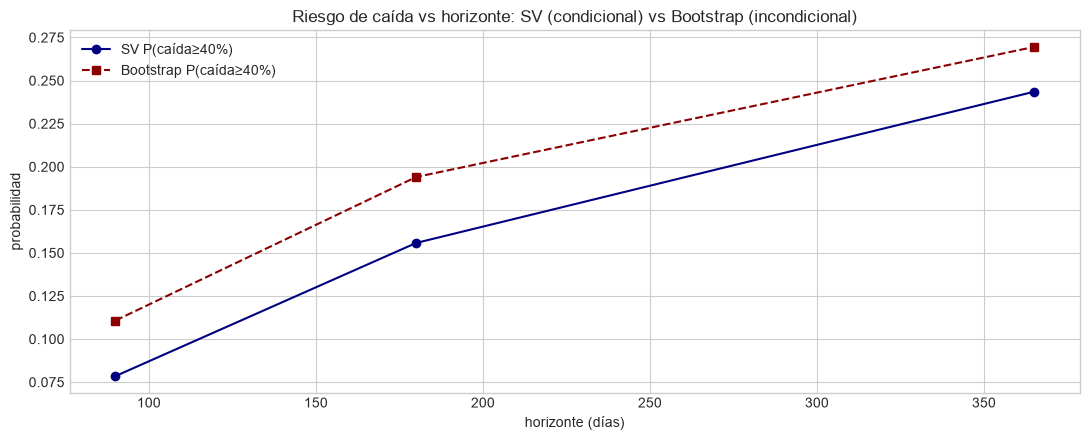

In [6]:
horizons=[90,180,365]
rows=[]
sv_paths_by_h={}; bs_paths_by_h={}
for h in horizons:
    svp = simulate_sv_trajectories_fast(mcmc, start_price, horizon_steps=h, n_trajectories=N_SIMS, seed=1)
    bsp = mc.simulate_paths(h)
    sv_paths_by_h[h]=svp; bs_paths_by_h[h]=bsp
    svr=summarize_sv_risk(svp); bsr=MonteCarloPriceSimulator.summarize_risk(bsp)
    # vol anualizada implícita (mediana de la vol realizada por trayectoria)
    sv_vol=np.median(np.log(svp/svp.shift()).std()*np.sqrt(252))
    bs_vol=np.median(np.log(bsp/bsp.shift()).std()*np.sqrt(252))
    rows.append({'horizonte_d':h,
                 'SV_P(caida>=20%)':svr['prob_drop_20pct_or_more'], 'BS_P(caida>=20%)':bsr['prob_drop_20pct_or_more'],
                 'SV_P(caida>=40%)':svr['prob_drop_40pct_or_more'], 'BS_P(caida>=40%)':bsr['prob_drop_40pct_or_more'],
                 'SV_vol_ann':sv_vol, 'BS_vol_ann':bs_vol})
tab=pd.DataFrame(rows).set_index('horizonte_d')
print(tab.to_string(float_format=lambda x: f'{x:.3f}'))

fig,ax=plt.subplots(figsize=(11,4.5))
ax.plot(horizons, tab['SV_P(caida>=40%)'], 'o-', color='navy', label='SV P(caída≥40%)')
ax.plot(horizons, tab['BS_P(caida>=40%)'], 's--', color='darkred', label='Bootstrap P(caída≥40%)')
ax.set_xlabel('horizonte (días)'); ax.set_ylabel('probabilidad'); ax.set_title('Riesgo de caída vs horizonte: SV (condicional) vs Bootstrap (incondicional)'); ax.legend()
plt.tight_layout(); plt.show()

## 6. Backtest de volatilidad y drawdown vs. 2024–2026 real

Como ambos modelos son *zero-drift*, no predicen el **nivel** (BTC tuvo un bull fuerte en 2024, por
encima del p95). La validación relevante es sobre **volatilidad y drawdown**: ¿dónde caen la
volatilidad y la caída máxima realizadas dentro de la distribución simulada por el SV?

> **Resultado (honesto):** la vol y el drawdown realizados caen en la **cola baja** de la
> distribución SV (percentiles ~2 y ~13). El SV, entrenado sobre 2012–2023 (con la volatilidad
> extrema de los primeros años de BTC), **sobre-proyecta** la volatilidad de 2024–2025, un periodo
> estructuralmente más calmo. Es una limitación a discutir (ver Cap. 8 / trabajo futuro).

Vol. anualizada realizada (test 365d): 42.6%  -> percentil 2 de la dist. SV
Max drawdown realizado:               9.4%  -> percentil 13 de la dist. SV


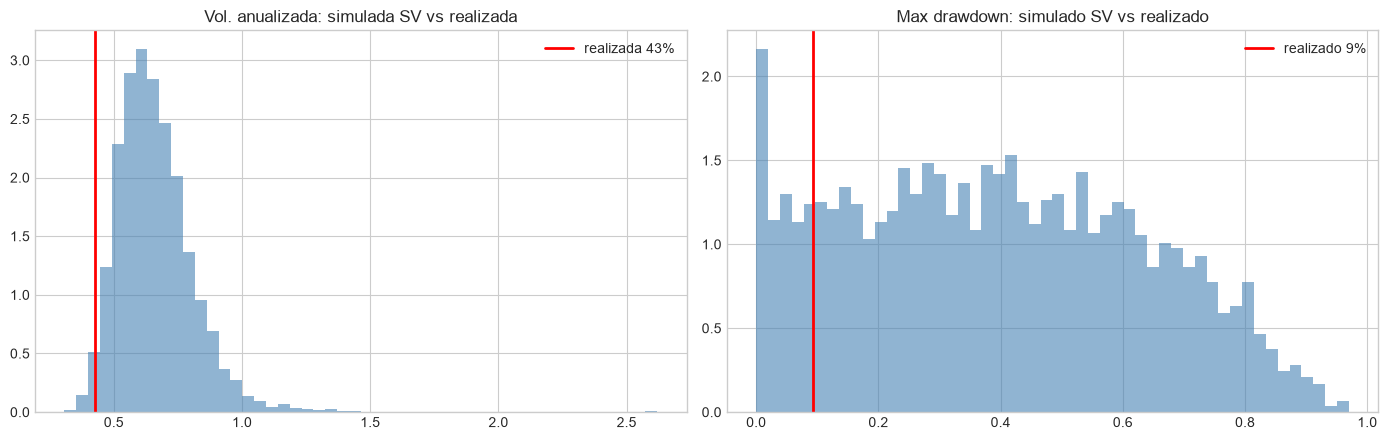

In [7]:
n_bt = min(H, len(price_te))
real_path = price_te.iloc[:n_bt].values
real_ret = np.diff(np.log(real_path))
real_vol_ann = real_ret.std()*np.sqrt(252)
real_maxdd = 1.0 - real_path.min()/real_path[0]

# distribuciones simuladas (SV) a n_bt pasos
svp_bt = simulate_sv_trajectories_fast(mcmc, start_price, horizon_steps=n_bt, n_trajectories=N_SIMS, seed=7)
sim_vol = np.log(svp_bt/svp_bt.shift()).std().values*np.sqrt(252)
sim_maxdd = (1.0 - svp_bt.min()/svp_bt.iloc[0]).values
vol_pct = float((sim_vol < real_vol_ann).mean()*100)
dd_pct  = float((sim_maxdd < real_maxdd).mean()*100)
print(f'Vol. anualizada realizada (test {n_bt}d): {real_vol_ann:.1%}  -> percentil {vol_pct:.0f} de la dist. SV')
print(f'Max drawdown realizado:               {real_maxdd:.1%}  -> percentil {dd_pct:.0f} de la dist. SV')

fig,axes=plt.subplots(1,2,figsize=(14,4.5))
axes[0].hist(sim_vol, bins=50, color='steelblue', alpha=0.6, density=True)
axes[0].axvline(real_vol_ann, color='red', lw=2, label=f'realizada {real_vol_ann:.0%}')
axes[0].set_title('Vol. anualizada: simulada SV vs realizada'); axes[0].legend()
axes[1].hist(sim_maxdd, bins=50, color='steelblue', alpha=0.6, density=True)
axes[1].axvline(real_maxdd, color='red', lw=2, label=f'realizado {real_maxdd:.0%}')
axes[1].set_title('Max drawdown: simulado SV vs realizado'); axes[1].legend()
plt.tight_layout(); plt.show()

## 7. Riesgo de liquidación (preview del Cap. 6)

Probabilidad de liquidación y pérdida esperada de las trayectorias SV a 365 d, para distintos LTV
iniciales (liquidación a LTV=0.80). La liquidación ocurre si $\min_t P_t/P_0 < \text{LTV}_0/0.80$.

In [8]:
liq_rows=[]
for ltv0 in [0.40,0.50,0.60,0.70]:
    r = summarize_sv_risk(sv_paths, init_ltv=ltv0, liq_ltv=0.80)
    liq_rows.append({'LTV_inicial':ltv0, 'umbral_caida':f'{(1-ltv0/0.80):.0%}',
                     'P(liquidacion)':r['prob_liquidation'], 'E[LGL]':r['mean_loss_given_liq'],
                     'ES95_loss':r['es95_loss']})
print(pd.DataFrame(liq_rows).set_index('LTV_inicial').to_string(float_format=lambda x: f'{x:.3f}'))

            umbral_caida  P(liquidacion)  E[LGL]  ES95_loss
LTV_inicial                                                
0.4                  50%           0.342   0.101      0.503
0.5                  38%           0.517   0.110      0.603
0.6                  25%           0.684   0.120      0.669
0.7                  13%           0.836   0.132      0.716


## 8. Conclusiones del Cap. 5

- Se generaron trayectorias SV **propagando incertidumbre epistémica** (muestreo de la posterior)
  y aleatórica, partiendo del estado de volatilidad actual $h_T$ (23% anualizado a fin de 2023).
- **SV vs Bootstrap:** a 365 d el riesgo de cola es comparable (el bootstrap de 12 años de BTC ya es
  muy fat-tailed). La diferencia se ve **por horizonte**: a 90 d el SV da menor riesgo (P(caída≥40%)
  7.9% vs 11.1% del bootstrap) porque es *condicional* al régimen calmo vigente; a 365 d convergen.
- **Backtest (vol/drawdown):** la vol (42.6%) y el drawdown (9.4%) realizados en 2024–2026 caen en la
  **cola baja** de la distribución SV → el modelo **sobre-proyecta** la volatilidad reciente por estar
  entrenado en la historia completa. Motiva usar una ventana más reciente o vol incondicional variable.
- **Riesgo de liquidación** cuantificado por LTV inicial (a 365 d: P(liq)=34% con LTV 0.40, 84% con 0.70)
  → insumo directo del pricing (Cap. 6).

**Siguiente:** Cap. 6-7 — modelo frecuencia-severidad Bayesiano, primas por plazo×LTV y buffer óptimo
(`05_pricing_buffer_bayesiano.ipynb`).